# B. Predictive baseline: how much energy *should* each floor have used?

A baseline predicts energy use from things the building operator cannot control, such as the weather and the
calendar. The difference between actual and predicted use is then a fair measure of performance. This is the standard
approach in measurement and verification (M&V) of energy savings. The baseline is the foundation for the comparison
(C), anomaly detection (D) and savings checks (F).

**Models, simplest first.** The simplest model that passes the accuracy test is the one reported.

1. **3-parameter change-point model, daily.** `kWh/day = b0 + b1·max(T_out − T_cp, 0)`. Energy stays at a flat level
   (`b0`) until the outdoor temperature `T_out` passes a change-point `T_cp`, then rises by `b1` for each extra degree.
   It is fitted separately for workdays and non-workdays (method from the ASHRAE Inverse Modeling Toolkit).
2. **TOWT (time-of-week and temperature), hourly.** One term for each of the 168 hours in a week, plus a term for
   outdoor temperature that can bend at set points, fitted separately for occupied and unoccupied hours (method from
   Lawrence Berkeley National Laboratory, LBNL).
3. **Gradient boosting, hourly.** A machine-learning model using weather and calendar inputs, which can pick up
   non-linear effects.

**Rules.** Only inputs outside the operator's control are used. Indoor temperature is left out because it is a result
of the cooling, not a cause (`baseline.py` checks this). **Accuracy test: ASHRAE Guideline 14 (G14).** Hourly CV(RMSE)
must be 30% or less and |NMBE| must be 10% or less. CV(RMSE) measures the typical size of the hourly errors, and NMBE
measures whether the model runs high or low overall; both are percentages of average use. **Time periods:** the models
are trained on Jul 2018 – Jun 2019, so every season is seen once, and tested on Jul – Dec 2019, which the models have
not seen.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="obj.round has no effect")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# `pip install -e .` from the repo root makes `sbanalytics` importable; this fallback works without it.
try:
    import sbanalytics
except ImportError:
    import sys
    from pathlib import Path
    sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sbanalytics").is_dir()) / "src"))

from sbanalytics import data as D, registry as R, viz
viz.setup()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)
from sbanalytics import baseline as B, analysis as A, config as C

In [2]:
h = D.load_hourly(None)
fh = B.floor_hourly(h)
fd = B.floor_daily(fh)
OFFICE = [2, 3, 4, 5, 6, 7]     # F1 has no AC schedule (Section 5 of 00a): excluded from schedule-based measures

## 1. Why a 12-month training period

The dashboard's zone models are trained on Mar–Sep 2019, to avoid the F5 zone 2/zone 4 meter transfer. For *floor*
totals that transfer does not matter, and seven warm months cannot teach a model what October to December look like:

In [3]:
short, _ = B.fit_hourly_ladder(fh, "total_kwh", train=A.TRAIN, splits={"test (Oct-Dec 2019)": A.TEST})
full, _ = B.fit_hourly_ladder(fh, "total_kwh")
cmp = pd.concat([
    short[(short.model == "TOWT") & short.split.str.startswith("test")].set_index("floor").nmbe.rename("NMBE % — trained Mar–Sep 2019"),
    full[(full.model == "TOWT") & full.split.str.startswith("test")].set_index("floor").nmbe.rename("NMBE % — trained Jul 2018–Jun 2019"),
], axis=1)
cmp.round(1)

,NMBE % — trained Mar–Sep 2019,NMBE % — trained Jul 2018–Jun 2019
floor,,
1,-8.6,-14.0
2,-11.9,-1.2
3,-8.6,-2.2
4,-6.4,3.4
5,-7.1,0.9
6,-1.4,1.9
7,-12.4,0.4


A negative NMBE means the model predicts more energy than the floor actually used. When trained on warm months only,
the model over-predicts every office floor in the test period. Training on a full year removes most of that bias.

## 2. The models on every floor

In [4]:
rows = []
for target in ("total_kwh", "ac_kwh"):
    m_h, pred_h = B.fit_hourly_ladder(fh, target)
    m_d, pred_d, params = B.fit_daily_changepoint(fd, target)
    rows.append(pd.concat([m_h, m_d]).assign(target=target))
    if target == "total_kwh":
        PRED_H, PRED_D, PARAMS = pred_h, pred_d, params
g14 = pd.concat(rows, ignore_index=True)
g14.to_csv(C.DATA_DERIVED / "baseline_g14.csv", index=False)

test = g14[g14.split.str.startswith("test")]
table = test.pivot_table(index=["target", "floor"], columns="model", values=["cv_rmse", "nmbe"]).round(1)
table

cv_rmse                  nmbe            
model           3PC daily   GBM  TOWT 3PC daily   GBM  TOWT
target    floor                                            
ac_kwh    1          42.4  66.3  62.8     -21.0 -20.4 -22.1
          2          14.6  35.9  34.9      -1.7  -2.3  -1.9
          3          16.4  32.1  34.1      -3.7  -5.2  -4.8
          4          17.4  34.5  32.6       4.7   3.5   4.0
          5          16.1  29.5  30.9       1.2   0.6   0.5
          6          15.8  29.3  30.7       5.4   3.6   4.5
          7          24.9  46.4  45.6      -2.3  -2.8  -3.8
total_kwh 1          20.2  33.7  28.6     -13.9 -18.3 -14.0
          2          13.2  29.9  29.4      -1.2  -1.7  -1.2
          3          11.7  22.9  24.3      -1.7  -2.4  -2.2
          4          13.3  22.9  22.7       3.5   2.6   3.4
          5          12.9  21.1  22.2       1.1   0.8   0.9
          6          10.2  19.3  19.7       2.4  -0.2   1.9
          7          19.8  36.4  35.4       1.1   1.7   0.4

In [5]:
def pick(g):
    order = ["3PC daily", "TOWT", "GBM"]
    ok = g[g.meets_g14].set_index("model")
    for m in order:
        if m in ok.index:
            return pd.Series({"model": m, "cv_rmse": ok.at[m, "cv_rmse"], "nmbe": ok.at[m, "nmbe"], "meets_g14": True})
    best = g.loc[g.cv_rmse.idxmin()]
    return pd.Series({"model": best.model, "cv_rmse": best.cv_rmse, "nmbe": best.nmbe, "meets_g14": False})

chosen = test.groupby(["target", "floor"]).apply(pick, include_groups=False)
chosen.to_csv(C.DATA_DERIVED / "baseline_chosen.csv")
chosen.round(1)

model  cv_rmse  nmbe  meets_g14
target    floor                                     
ac_kwh    1      3PC daily     42.4 -21.0      False
          2      3PC daily     14.6  -1.7       True
          3      3PC daily     16.4  -3.7       True
          4      3PC daily     17.4   4.7       True
          5      3PC daily     16.1   1.2       True
          6      3PC daily     15.8   5.4       True
          7      3PC daily     24.9  -2.3       True
total_kwh 1      3PC daily     20.2 -13.9      False
          2      3PC daily     13.2  -1.2       True
          3      3PC daily     11.7  -1.7       True
          4      3PC daily     13.3   3.5       True
          5      3PC daily     12.9   1.1       True
          6      3PC daily     10.2   2.4       True
          7      3PC daily     19.8   1.1       True

In [6]:
hourly_ok = test[(test.target == "total_kwh") & (test.model != "3PC daily")].groupby("floor").meets_g14.any()
print("Floors with an hourly total-energy baseline that meets G14 out of sample:", [f for f, ok in hourly_ok.items() if ok])
print("Floors where no hourly model meets G14:", [f for f, ok in hourly_ok.items() if not ok])

Floors with an hourly total-energy baseline that meets G14 out of sample: [2, 3, 4, 5, 6]
Floors where no hourly model meets G14: [1, 7]


## 3. What the change-point model says about each floor

From the workday model: the outdoor temperature above which cooling energy starts to rise (`cp`), and how quickly it
rises (`b1`, in kWh/day per °C). When two similar floors differ, the one with the steeper slope reacts more strongly
to heat. That could be down to the building fabric, the setpoint or the equipment.

In [7]:
cp = pd.DataFrame([{"floor": f, "regime": r, "balance_point_c": m.get("cp"), "kwh_per_day_per_c": m.get("b1"),
                    "base_kwh_per_day": m.get("b0"), "r2": m.get("r2"), "days": m.get("n")}
                   for (f, r), m in PARAMS.items()])
cp.to_csv(C.DATA_DERIVED / "changepoint_params.csv", index=False)
cp[cp.regime == "workday"].round(2)

,floor,regime,balance_point_c,kwh_per_day_per_c,base_kwh_per_day,r2,days
0,1,workday,29.97,18.88,2655.71,0.00,265
2,2,workday,26.33,47.35,834.24,0.43,226
4,3,workday,26.45,38.30,704.68,0.44,190
6,4,workday,26.42,22.18,687.27,0.20,223
8,5,workday,26.35,44.78,672.44,0.51,221
10,6,workday,26.31,37.93,665.42,0.46,241
12,7,workday,26.33,70.08,857.36,0.59,226


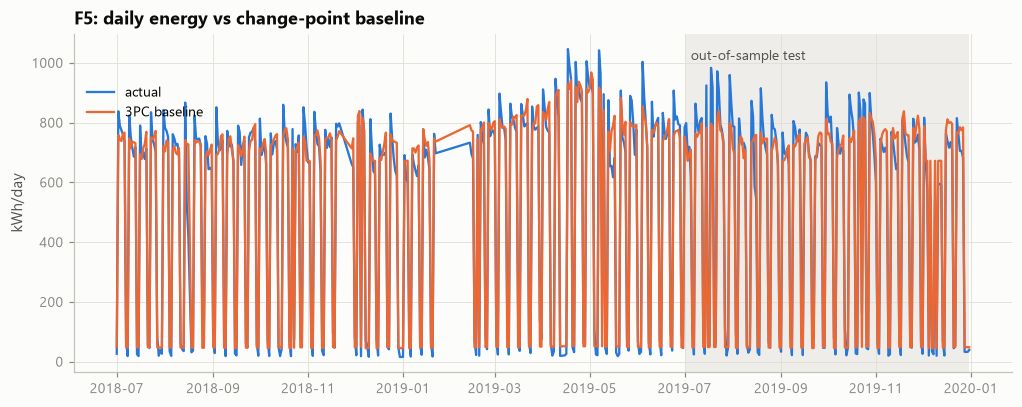

In [8]:
FLOOR = 5
d = PRED_D[PRED_D.floor == FLOOR]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(d.day, d.total_kwh, color=viz.CATEGORICAL[0], label="actual", lw=1.5)
ax.plot(d.day, d.pred, color=viz.CATEGORICAL[1], label="3PC baseline", lw=1.5)
ax.axvspan(pd.Timestamp("2019-07-01"), pd.Timestamp("2019-12-31"), color=viz.GRID, alpha=0.5, lw=0)
ax.text(pd.Timestamp("2019-07-05"), ax.get_ylim()[1] * 0.95, "out-of-sample test", color=viz.INK_2, fontsize=9, va="top")
ax.set_ylabel("kWh/day"); ax.set_title(f"F{FLOOR}: daily energy vs change-point baseline"); ax.legend(loc="upper left", bbox_to_anchor=(0, 0.88))

**How to use this.** Where a floor has a baseline that meets G14, the difference between actual and predicted use
after a change (to a setpoint or schedule, for example) gives a defensible estimate of the savings. This follows
IPMVP Option C, the international protocol for measuring savings on a whole building or floor. Where no model passes,
savings have to be measured with a controlled pilot instead (see the pilot design in `06`).